# 02 · Análisis explicativo: qué features se asocian con depresión y ansiedad

Modelos logit (statsmodels) sobre la muestra de desarrollo (`outputs/desarrollo.csv`, de `01_datos`). Las features se estandarizan (z), así que cada coeficiente es el cambio en log-odds por 1 DE y `exp(coef)` es el odds ratio (OR) por 1 DE.

1. Modelo base: solo sexo.
2. Tamizaje: un logit por feature y tarea, `y ~ sexo + feature` (80 por desenlace), con corrección de Benjamini-Hochberg (BH).
3. Robustez: lo mismo agregando la tasa de muestreo del audio (equipo) como covariable.
4. Interacción con sexo: `y ~ sexo * feature`, porque algunos estudios reportan efectos de signo opuesto por sexo.
5. Modelo multivariable por tarea: las 20 features + sexo juntas, con efectos marginales.

Solo se muestran coeficientes, valores p y conteos.

## Housekeeping

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.iolib.summary2 import summary_col
from statsmodels.stats.outliers_influence import variance_inflation_factor

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

%matplotlib inline

In [2]:
datos = pd.read_csv("outputs/desarrollo.csv", dtype={"participant_id": str})

TAREAS = ["DESCRIPCION", "PREGUNTA1", "PREGUNTA2", "TEXTO_EL_ABUELO"]
OBJETIVOS = {"dep": "Depresión (PHQ-9 ≥ 10)", "ans": "Ansiedad (GAD-7 ≥ 10)"}
FEATURES = [c.split("__")[0] for c in datos.columns if c.endswith("__DESCRIPCION") and not c.startswith(("tasa", "duracion"))]
CORTO = {
    "F0semitoneFrom27.5Hz_sma3nz_amean": "F0_media", "F0semitoneFrom27.5Hz_sma3nz_stddevNorm": "F0_var",
    "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2": "F0_rango", "jitterLocal_sma3nz_amean": "jitter",
    "shimmerLocaldB_sma3nz_amean": "shimmer", "HNRdBACF_sma3nz_amean": "HNR", "vw_a_f1_hz_mean": "F1_a",
    "vw_a_f2_hz_mean": "F2_a", "loudness_sma3_stddevNorm": "loudness_var", "alphaRatioV_sma3nz_amean": "alpha_ratio",
    "hammarbergIndexV_sma3nz_amean": "hammarberg", "slopeV0-500_sma3nz_amean": "slope_0_500",
    "mfcc1V_sma3nz_amean": "mfcc1", "mfcc2V_sma3nz_amean": "mfcc2", "mfcc3V_sma3nz_amean": "mfcc3",
    "mfcc4V_sma3nz_amean": "mfcc4", "MeanVoicedSegmentLengthSec": "seg_sonoro", "pause_time_ratio": "pausa_ratio",
    "pause_mean_s": "pausa_media", "articulation_rate_vps": "vel_articulacion",
}

# Variables estandarizadas con nombres válidos para fórmulas: <corto>_<TAREA>
df = datos[["participant_id", "dep", "ans", "sexo"] + [f"tasa__{t}" for t in TAREAS]].copy()
for f in FEATURES:
    for t in TAREAS:
        x = datos[f"{f}__{t}"]
        df[f"{CORTO[f]}_{t}"] = (x - x.mean()) / x.std()
# Tasa de muestreo como covariable: las tasas con menos de 10 audios en la tarea se juntan en "otra" (-1),
# porque una categoría con 1 o 2 audios deja el modelo sin solución (matriz singular).
for t in TAREAS:
    c = f"tasa__{t}"
    n = df[c].map(df[c].value_counts())
    df[c] = df[c].where(n >= 10, -1).astype(int)
print("Categorías de tasa por tarea:", {t: df[f"tasa__{t}"].value_counts().to_dict() for t in TAREAS})
print(f"Sujetos: {len(df)} | features estandarizadas: {len(FEATURES) * len(TAREAS)}")
print({o: f"{df[o].sum()} casos ({df[o].mean():.3f})" for o in OBJETIVOS})

Categorías de tasa por tarea: {'DESCRIPCION': {44100: 255, 48000: 54, 22050: 42, -1: 5}, 'PREGUNTA1': {44100: 255, 48000: 55, 22050: 41, -1: 5}, 'PREGUNTA2': {44100: 255, 48000: 55, 22050: 41, -1: 5}, 'TEXTO_EL_ABUELO': {44100: 255, 48000: 54, 22050: 42, -1: 5}}
Sujetos: 356 | features estandarizadas: 80
{'dep': '140 casos (0.393)', 'ans': '106 casos (0.298)'}


## 1. Modelo base: solo sexo

In [3]:
for obj, nombre in OBJETIVOS.items():
    base = smf.logit(f"{obj} ~ sexo", data=df).fit(disp=0)
    print(f"==================== {nombre}")
    print(base.summary2())
    print(f"OR de sexo: {np.exp(base.params['sexo']):.3f}")
    print(base.get_margeff().summary())

==================== Depresión (PHQ-9 ≥ 10)
                         Results: Logit
Model:              Logit            Method:           MLE       
Dependent Variable: dep              Pseudo R-squared: 0.041     
Date:               2026-11-09 10:21 AIC:              461.4489  
No. Observations:   356              BIC:              469.1988  
Df Model:           1                Log-Likelihood:   -228.72   
Df Residuals:       354              LL-Null:          -238.59   
Converged:          1.0000           LLR p-value:      8.9584e-06
No. Iterations:     5.0000           Scale:            1.0000    
------------------------------------------------------------------
               Coef.   Std.Err.     z     P>|z|    [0.025   0.975]
------------------------------------------------------------------
Intercept     -0.0202    0.1421  -0.1421  0.8870  -0.2988   0.2584
sexo          -0.9957    0.2294  -4.3401  0.0000  -1.4454  -0.5461

OR de sexo: 0.369
        Logit Marginal Effects    

## 2. Tamizaje: un logit por feature, ajustado por sexo

`y ~ sexo + feature` para cada feature y tarea. `q` es el valor p corregido por BH dentro de cada desenlace (80 pruebas).

In [4]:
def tamizaje(obj, covariables="sexo", interaccion=False):
    filas = []
    for f in FEATURES:
        for t in TAREAS:
            v = f"{CORTO[f]}_{t}"
            cov = covariables.replace("{t}", t)
            formula = f"{obj} ~ {cov} * {v}" if interaccion else f"{obj} ~ {cov} + {v}"
            termino = f"sexo:{v}" if interaccion else v
            try:
                m = smf.logit(formula, data=df).fit(disp=0, maxiter=200)
            except Exception as exc:  # p. ej., separación perfecta con una tasa de muestreo poco frecuente
                print(f"No ajusta {formula}: {type(exc).__name__}")
                continue
            ci = m.conf_int().loc[termino]
            filas.append({"feature": CORTO[f], "tarea": t, "n": int(m.nobs), "coef": m.params[termino],
                          "OR": np.exp(m.params[termino]), "OR_inf": np.exp(ci[0]), "OR_sup": np.exp(ci[1]),
                          "p": m.pvalues[termino]})
    res = pd.DataFrame(filas)
    res["q_BH"] = multipletests(res["p"], method="fdr_bh")[1]
    return res

resultados = {obj: tamizaje(obj) for obj in OBJETIVOS}
for obj, nombre in OBJETIVOS.items():
    r = resultados[obj]
    print(f"==================== {nombre}")
    print(f"p < 0,05: {(r['p'] < 0.05).sum()} de {len(r)} (por azar se esperan {0.05 * len(r):.0f}) | q_BH < 0,05: {(r['q_BH'] < 0.05).sum()}")
    display(r.sort_values("p").head(10).round(4))

==================== Depresión (PHQ-9 ≥ 10)
p < 0,05: 0 de 80 (por azar se esperan 4) | q_BH < 0,05: 0


,feature,tarea,n,coef,OR,OR_inf,OR_sup,p,q_BH
61,mfcc4,PREGUNTA1,356,0.2865,1.3318,0.9845,1.8015,0.0631,0.9989
28,F2_a,DESCRIPCION,354,0.3240,1.3827,0.9814,1.9480,0.0639,0.9989
66,seg_sonoro,PREGUNTA2,356,-0.1828,0.8330,0.6627,1.0470,0.1173,0.9989
55,mfcc2,TEXTO_EL_ABUELO,356,0.1800,1.1972,0.9513,1.5067,0.1249,0.9989
62,mfcc4,PREGUNTA2,356,0.2234,1.2503,0.9332,1.6751,0.1344,0.9989
79,vel_articulacion,TEXTO_EL_ABUELO,356,-0.1650,0.8479,0.6747,1.0657,0.1572,0.9989
12,jitter,DESCRIPCION,356,-0.1749,0.8396,0.6588,1.0700,0.1576,0.9989
11,F0_rango,TEXTO_EL_ABUELO,356,-0.1632,0.8495,0.6742,1.0702,0.1663,0.9989
31,F2_a,TEXTO_EL_ABUELO,356,0.2640,1.3022,0.8929,1.8990,0.1702,0.9989
20,HNR,DESCRIPCION,356,0.2408,1.2723,0.8556,1.8918,0.2342,0.9989


==================== Ansiedad (GAD-7 ≥ 10)
p < 0,05: 0 de 80 (por azar se esperan 4) | q_BH < 0,05: 0


,feature,tarea,n,coef,OR,OR_inf,OR_sup,p,q_BH
74,pausa_media,PREGUNTA2,356,-0.2572,0.7732,0.5408,1.1057,0.1587,0.9998
55,mfcc2,TEXTO_EL_ABUELO,356,0.1702,1.1856,0.9313,1.5091,0.1669,0.9998
67,seg_sonoro,TEXTO_EL_ABUELO,356,-0.1595,0.8525,0.6699,1.0850,0.1946,0.9998
44,slope_0_500,DESCRIPCION,356,0.1586,1.1719,0.9187,1.4949,0.2016,0.9998
40,hammarberg,DESCRIPCION,356,-0.1245,0.8829,0.6988,1.1156,0.2967,0.9998
64,seg_sonoro,DESCRIPCION,356,-0.1232,0.8841,0.6958,1.1234,0.3135,0.9998
46,slope_0_500,PREGUNTA2,356,0.1233,1.1312,0.8887,1.4400,0.3166,0.9998
11,F0_rango,TEXTO_EL_ABUELO,356,-0.1262,0.8815,0.6882,1.1291,0.3179,0.9998
75,pausa_media,TEXTO_EL_ABUELO,356,0.1154,1.1223,0.8948,1.4076,0.3180,0.9998
27,F1_a,TEXTO_EL_ABUELO,356,-0.1616,0.8508,0.6159,1.1753,0.3270,0.9998


Mapa de coeficientes (log-odds por 1 DE); los asteriscos marcan p < 0,05 sin corregir:

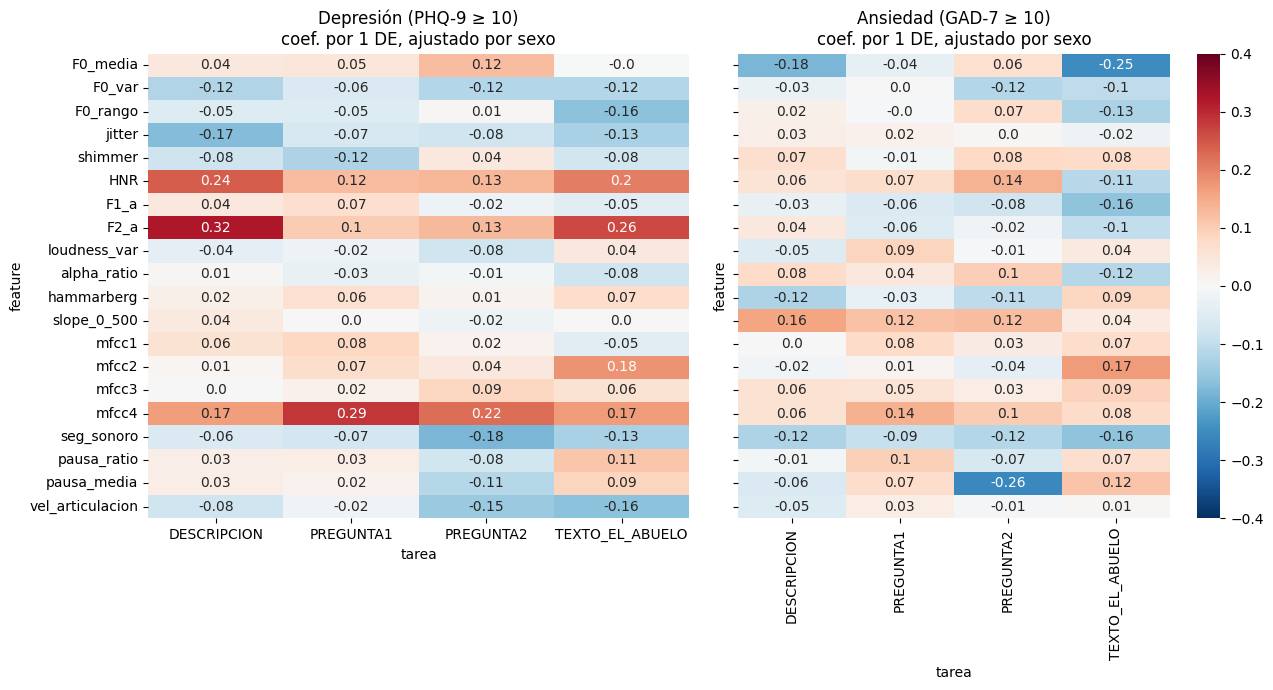

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
for a, (obj, nombre) in zip(ax, OBJETIVOS.items()):
    r = resultados[obj]
    coef = r.pivot(index="feature", columns="tarea", values="coef").loc[[CORTO[f] for f in FEATURES], TAREAS]
    p = r.pivot(index="feature", columns="tarea", values="p").loc[coef.index, TAREAS]
    etiquetas = coef.round(2).astype(str) + np.where(p < 0.05, "*", "")
    sns.heatmap(coef, annot=etiquetas, fmt="", cmap="RdBu_r", center=0, vmin=-0.4, vmax=0.4, ax=a, cbar=a is ax[-1])
    a.set_title(f"{nombre}\ncoef. por 1 DE, ajustado por sexo")
plt.tight_layout(); plt.show()

## 3. Robustez: ajuste por tasa de muestreo

Se agrega `C(tasa__<TAREA>)` (tasa de muestreo del audio de esa tarea) como covariable. Si una asociación desaparece, podría deberse al equipo de grabación y no a la voz.

In [6]:
robustez = {obj: tamizaje(obj, covariables="sexo + C(tasa__{t})") for obj in OBJETIVOS}
for obj, nombre in OBJETIVOS.items():
    comp = resultados[obj][["feature", "tarea", "coef", "p"]].merge(
        robustez[obj][["feature", "tarea", "coef", "p", "q_BH"]], on=["feature", "tarea"], suffixes=("", "_con_tasa"))
    print(f"==================== {nombre}")
    print(f"p < 0,05 con tasa: {(comp['p_con_tasa'] < 0.05).sum()} | q_BH < 0,05 con tasa: {(comp['q_BH'] < 0.05).sum()}")
    print(f"Correlación entre coeficientes sin y con tasa: {comp['coef'].corr(comp['coef_con_tasa']):.3f}")
    display(comp.sort_values("p").head(10).round(4))

==================== Depresión (PHQ-9 ≥ 10)
p < 0,05 con tasa: 1 | q_BH < 0,05 con tasa: 0
Correlación entre coeficientes sin y con tasa: 0.984


,feature,tarea,coef,p,coef_con_tasa,p_con_tasa,q_BH
61,mfcc4,PREGUNTA1,0.2865,0.0631,0.3229,0.0434,0.9152
28,F2_a,DESCRIPCION,0.3240,0.0639,0.3205,0.0724,0.9152
66,seg_sonoro,PREGUNTA2,-0.1828,0.1173,-0.1964,0.0982,0.9152
55,mfcc2,TEXTO_EL_ABUELO,0.1800,0.1249,0.1853,0.1182,0.9152
62,mfcc4,PREGUNTA2,0.2234,0.1344,0.2678,0.0871,0.9152
79,vel_articulacion,TEXTO_EL_ABUELO,-0.1650,0.1572,-0.1992,0.0937,0.9152
12,jitter,DESCRIPCION,-0.1749,0.1576,-0.2324,0.0706,0.9152
11,F0_rango,TEXTO_EL_ABUELO,-0.1632,0.1663,-0.1893,0.1198,0.9152
31,F2_a,TEXTO_EL_ABUELO,0.2640,0.1702,0.2725,0.1631,0.9319
20,HNR,DESCRIPCION,0.2408,0.2342,0.2991,0.1487,0.9152


==================== Ansiedad (GAD-7 ≥ 10)
p < 0,05 con tasa: 0 | q_BH < 0,05 con tasa: 0
Correlación entre coeficientes sin y con tasa: 0.957


,feature,tarea,coef,p,coef_con_tasa,p_con_tasa,q_BH
74,pausa_media,PREGUNTA2,-0.2572,0.1587,-0.1966,0.2802,0.9901
55,mfcc2,TEXTO_EL_ABUELO,0.1702,0.1669,0.1766,0.1535,0.9901
67,seg_sonoro,TEXTO_EL_ABUELO,-0.1595,0.1946,-0.1712,0.1685,0.9901
44,slope_0_500,DESCRIPCION,0.1586,0.2016,0.1835,0.1782,0.9901
40,hammarberg,DESCRIPCION,-0.1245,0.2967,-0.1257,0.2984,0.9901
64,seg_sonoro,DESCRIPCION,-0.1232,0.3135,-0.1153,0.3523,0.9901
46,slope_0_500,PREGUNTA2,0.1233,0.3166,0.1192,0.3736,0.9901
11,F0_rango,TEXTO_EL_ABUELO,-0.1262,0.3179,-0.1503,0.2500,0.9901
75,pausa_media,TEXTO_EL_ABUELO,0.1154,0.3180,0.1105,0.3479,0.9901
27,F1_a,TEXTO_EL_ABUELO,-0.1616,0.3270,-0.1755,0.2896,0.9901


## 4. Interacción con sexo

`y ~ sexo * feature`: el término `sexo:feature` mide si la asociación cambia entre los dos grupos de `sexo`. BH sobre las 80 pruebas de cada desenlace.

In [7]:
interaccion = {obj: tamizaje(obj, interaccion=True) for obj in OBJETIVOS}
for obj, nombre in OBJETIVOS.items():
    r = interaccion[obj]
    print(f"==================== {nombre}")
    print(f"p < 0,05: {(r['p'] < 0.05).sum()} de {len(r)} | q_BH < 0,05: {(r['q_BH'] < 0.05).sum()}")
    display(r.sort_values("p").head(8).round(4))

==================== Depresión (PHQ-9 ≥ 10)
p < 0,05: 1 de 80 | q_BH < 0,05: 0


,feature,tarea,n,coef,OR,OR_inf,OR_sup,p,q_BH
78,vel_articulacion,PREGUNTA2,354,1.0112,2.7490,1.1703,6.4573,0.0203,0.992
74,pausa_media,PREGUNTA2,356,-0.8519,0.4266,0.1737,1.0478,0.0632,0.992
32,loudness_var,DESCRIPCION,356,-0.4367,0.6462,0.4017,1.0396,0.0719,0.992
51,mfcc1,TEXTO_EL_ABUELO,356,0.4006,1.4927,0.9320,2.3908,0.0955,0.992
72,pausa_media,DESCRIPCION,355,-0.3988,0.6711,0.4134,1.0894,0.1066,0.992
42,hammarberg,PREGUNTA2,356,-0.3542,0.7018,0.4442,1.1086,0.1290,0.992
54,mfcc2,PREGUNTA2,356,-0.3524,0.7030,0.4458,1.1087,0.1295,0.992
38,alpha_ratio,PREGUNTA2,356,0.3460,1.4134,0.8982,2.2241,0.1347,0.992


==================== Ansiedad (GAD-7 ≥ 10)
p < 0,05: 3 de 80 | q_BH < 0,05: 0


,feature,tarea,n,coef,OR,OR_inf,OR_sup,p,q_BH
59,mfcc3,TEXTO_EL_ABUELO,356,-0.5705,0.5652,0.3300,0.9681,0.0377,0.9979
78,vel_articulacion,PREGUNTA2,354,0.6851,1.9840,1.0240,3.8440,0.0423,0.9979
38,alpha_ratio,PREGUNTA2,356,0.5027,1.6531,1.0107,2.7038,0.0452,0.9979
42,hammarberg,PREGUNTA2,356,-0.4598,0.6314,0.3847,1.0365,0.0690,0.9979
54,mfcc2,PREGUNTA2,356,-0.3985,0.6713,0.4148,1.0865,0.1047,0.9979
51,mfcc1,TEXTO_EL_ABUELO,356,0.3970,1.4873,0.9029,2.4499,0.1190,0.9979
24,F1_a,DESCRIPCION,354,0.5340,1.7058,0.8307,3.5028,0.1458,0.9979
46,slope_0_500,PREGUNTA2,356,0.3552,1.4265,0.8665,2.3486,0.1626,0.9979


## 5. Modelo multivariable por tarea

Las 20 features + sexo en un solo logit por tarea (filas con faltantes se descartan). Antes, el factor de inflación de varianza (VIF): valores > 10 indican colinealidad fuerte y coeficientes inestables.

In [8]:
vif = {}
for t in TAREAS:
    X = sm.add_constant(df[["sexo"] + [f"{CORTO[f]}_{t}" for f in FEATURES]].dropna())
    vif[t] = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
                       index=[c.replace(f"_{t}", "") for c in X.columns[1:]])
vif = pd.DataFrame(vif)
display(vif.round(1).sort_values("DESCRIPCION", ascending=False))
print("VIF > 10:", {t: list(vif.index[vif[t] > 10]) for t in TAREAS})

,DESCRIPCION,PREGUNTA1,PREGUNTA2,TEXTO_EL_ABUELO
F0_media,31.8,29.8,28.2,46.2
HNR,23.8,24.7,21.9,34.0
alpha_ratio,18.5,21.0,22.4,17.6
hammarberg,12.7,14.6,15.1,12.8
sexo,8.0,7.6,7.5,7.9
mfcc2,7.5,7.0,7.0,9.3
shimmer,6.9,10.3,10.8,11.6
mfcc1,4.3,4.4,4.5,4.8
F2_a,3.7,4.3,3.7,5.3
pausa_ratio,3.6,4.3,3.6,3.5


VIF > 10: {'DESCRIPCION': ['F0_media', 'HNR', 'alpha_ratio', 'hammarberg'], 'PREGUNTA1': ['F0_media', 'shimmer', 'HNR', 'alpha_ratio', 'hammarberg'], 'PREGUNTA2': ['F0_media', 'shimmer', 'HNR', 'alpha_ratio', 'hammarberg'], 'TEXTO_EL_ABUELO': ['F0_media', 'shimmer', 'HNR', 'alpha_ratio', 'hammarberg']}


In [9]:
multi = {}
for obj, nombre in OBJETIVOS.items():
    modelos = []
    for t in TAREAS:
        # columnas sin el sufijo de la tarea, para que las 4 columnas de la tabla compartan filas
        d_t = df[[obj, "sexo"] + [f"{CORTO[f]}_{t}" for f in FEATURES]].rename(columns=lambda c: c.replace(f"_{t}", ""))
        formula = f"{obj} ~ sexo + " + " + ".join(CORTO[f] for f in FEATURES)
        m = smf.logit(formula, data=d_t).fit(disp=0, maxiter=200)
        modelos.append(m); multi[(obj, t)] = m
    print(f"==================== {nombre}")
    print(summary_col(modelos, model_names=TAREAS, stars=True, float_format="%.3f",
                      info_dict={"N": lambda r: f"{int(r.nobs)}", "Pseudo R2": lambda r: f"{r.prsquared:.3f}",
                                 "LLR p": lambda r: f"{r.llr_pvalue:.4f}"}))

==================== Depresión (PHQ-9 ≥ 10)



                 DESCRIPCION PREGUNTA1 PREGUNTA2 TEXTO_EL_ABUELO
----------------------------------------------------------------
Intercept        -0.191      -0.067    -0.074    0.008          
                 (0.315)     (0.307)   (0.306)   (0.314)        
sexo             -0.687      -0.959    -0.960    -1.123*        
                 (0.670)     (0.649)   (0.643)   (0.670)        
F0_media         -1.096      0.054     -0.140    -1.027         
                 (0.673)     (0.643)   (0.619)   (0.793)        
F0_var           0.022       -0.003    -0.172    -0.049         
                 (0.178)     (0.190)   (0.229)   (0.207)        
F0_rango         0.104       0.022     0.160     -0.084         
                 (0.142)     (0.152)   (0.176)   (0.175)        
jitter           -0.386*     -0.095    -0.118    -0.133         
                 (0.226)     (0.248)   (0.276)   (0.259)        
shimmer          0.386       -0.187    0.094     0.005          
                 (0.320)

==================== Ansiedad (GAD-7 ≥ 10)



                 DESCRIPCION PREGUNTA1 PREGUNTA2 TEXTO_EL_ABUELO
----------------------------------------------------------------
Intercept        -0.500      -0.553*   -0.546*   -0.303         
                 (0.330)     (0.321)   (0.317)   (0.325)        
sexo             -0.906      -0.839    -0.888    -1.368*        
                 (0.710)     (0.684)   (0.673)   (0.705)        
F0_media         -0.567      0.569     0.114     0.333          
                 (0.699)     (0.675)   (0.649)   (0.818)        
F0_var           -0.058      0.005     -0.453*   -0.228         
                 (0.188)     (0.198)   (0.246)   (0.226)        
F0_rango         0.088       0.017     0.250     -0.086         
                 (0.145)     (0.159)   (0.185)   (0.184)        
jitter           -0.113      -0.093    0.152     0.012          
                 (0.228)     (0.260)   (0.293)   (0.272)        
shimmer          0.320       0.063     -0.043    -0.121         
                 (0.333)

¿Las 20 features agregan algo por sobre el sexo? El `LLR p` de la tabla compara contra un modelo vacío y lo domina el sexo; la prueba correcta es la razón de verosimilitud del modelo completo contra el modelo con **solo sexo**, ajustado en las mismas filas (20 grados de libertad):

In [10]:
from scipy import stats
filas = []
for obj in OBJETIVOS:
    for t in TAREAS:
        m = multi[(obj, t)]
        base = smf.logit(f"{obj} ~ sexo", data=m.model.data.frame.loc[m.model.data.row_labels]).fit(disp=0)
        lr = 2 * (m.llf - base.llf)
        gl = int(m.df_model - base.df_model)
        filas.append({"objetivo": obj, "tarea": t, "n": int(m.nobs), "pseudoR2_solo_sexo": base.prsquared,
                      "pseudoR2_con_features": m.prsquared, "LR": lr, "gl": gl, "p": stats.chi2.sf(lr, gl)})
lr_tabla = pd.DataFrame(filas)
display(lr_tabla.round(4))

,objetivo,tarea,n,pseudoR2_solo_sexo,pseudoR2_con_features,LR,gl,p
0,dep,DESCRIPCION,353,0.0391,0.0781,18.4290,20,0.5592
1,dep,PREGUNTA1,354,0.0397,0.0678,13.3042,20,0.8640
2,dep,PREGUNTA2,354,0.0397,0.0740,16.2089,20,0.7036
3,dep,TEXTO_EL_ABUELO,356,0.0413,0.0789,17.9208,20,0.5926
4,ans,DESCRIPCION,353,0.0181,0.0412,9.9563,20,0.9690
5,ans,PREGUNTA1,354,0.0170,0.0358,8.0335,20,0.9916
6,ans,PREGUNTA2,354,0.0182,0.0511,14.1536,20,0.8226
7,ans,TEXTO_EL_ABUELO,356,0.0185,0.0420,10.1846,20,0.9647


Efectos marginales promedio (dy/dx: cambio en la probabilidad por 1 DE) del modelo multivariable de la tarea con menor p en la prueba anterior, para cada desenlace:

In [11]:
for obj, nombre in OBJETIVOS.items():
    fila = lr_tabla[lr_tabla["objetivo"] == obj].sort_values("p").iloc[0]
    print(f"==================== {nombre} · {fila['tarea']} (LR contra solo sexo: p = {fila['p']:.4f})")
    print(multi[(obj, fila["tarea"])].get_margeff().summary())

==================== Depresión (PHQ-9 ≥ 10) · DESCRIPCION (LR contra solo sexo: p = 0.5592)
        Logit Marginal Effects       
Dep. Variable:                    dep
Method:                          dydx
At:                           overall
                      dy/dx    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
sexo                -0.1477      0.143     -1.032      0.302      -0.428       0.133
F0_media            -0.2356      0.143     -1.649      0.099      -0.516       0.044
F0_var               0.0047      0.038      0.123      0.902      -0.070       0.080
F0_rango             0.0223      0.030      0.732      0.464      -0.037       0.082
jitter              -0.0830      0.048     -1.731      0.083      -0.177       0.011
shimmer              0.0830      0.068      1.217      0.224      -0.051       0.217
HNR                  0.2631      0.126      2.083      0.037       0.016    

## 6. Guardar resultados

In [12]:
for obj in OBJETIVOS:
    resultados[obj].assign(objetivo=obj, modelo="sexo + feature").to_csv(f"outputs/tamizaje_{obj}.csv", index=False)
    robustez[obj].assign(objetivo=obj, modelo="sexo + tasa + feature").to_csv(f"outputs/tamizaje_tasa_{obj}.csv", index=False)
    interaccion[obj].assign(objetivo=obj, modelo="sexo * feature").to_csv(f"outputs/interaccion_sexo_{obj}.csv", index=False)
print("Guardados en outputs/: tamizaje_*.csv, tamizaje_tasa_*.csv, interaccion_sexo_*.csv")

Guardados en outputs/: tamizaje_*.csv, tamizaje_tasa_*.csv, interaccion_sexo_*.csv


## Lectura de resultados

**Sexo (modelo base)**
- Depresión: OR = 0,37 (p < 0,001), pseudo R² 0,041.
- Ansiedad: OR = 0,51 (p = 0,005), pseudo R² 0,019.

**Tamizaje `y ~ sexo + feature` (80 pruebas por desenlace)**
- Ninguna feature tiene p < 0,05, en ninguno de los dos desenlaces (por azar se esperaban 4). Ninguna tiene q_BH < 0,05.
- Las más cercanas fueron MFCC4 de PREGUNTA1 (OR = 1,33 por DE, p = 0,063) y F2 de /a/ de DESCRIPCION (OR = 1,38, p = 0,064) en depresión, y pausa_media de PREGUNTA2 (OR = 0,77, p = 0,159) en ansiedad.
- Las diferencias de `01` (por ejemplo, d = 0,50 en F2 de /a/) casi desaparecen al ajustar por sexo.

**Robustez con la tasa de muestreo**
- Los coeficientes casi no cambian: la correlación con los del tamizaje es 0,984 en depresión y 0,957 en ansiedad.
- Una prueba queda con p < 0,05 (MFCC4 de PREGUNTA1 en depresión, p = 0,043; q = 0,92) y ninguna con q < 0,05.

**Interacción con sexo**
- p < 0,05 en 1 de 80 pruebas en depresión y 3 de 80 en ansiedad, todas con q_BH > 0,99.
- `vel_articulacion` de PREGUNTA2 aparece en los dos desenlaces. Antes de interpretarla, revisar los valores extremos de esa feature (ver `01`).

**Modelo multivariable por tarea**
- VIF > 10 en F0 media, HNR, alpha ratio y Hammarberg en todas las tareas, y en shimmer en PREGUNTA1, PREGUNTA2 y TEXTO_EL_ABUELO: sus coeficientes individuales no son interpretables.
- La prueba de razón de verosimilitud de las 20 features por sobre solo sexo no es significativa en ninguna tarea:
  - Depresión: p entre 0,56 y 0,86 (el pseudo R² sube de ~0,04 a 0,07–0,08).
  - Ansiedad: p entre 0,82 y 0,99.

**En resumen**: con n = 356, las 20 features CORE no muestran asociación con depresión ni ansiedad más allá del sexo, ni una por una ni en conjunto.